This test is on
1. i.i.d. rayleigh fading channel
2. 4*4 MIMO channel
3. 1000 symbols per channel
4. total of 1000 channels

ver 11.24.04.35


In [1]:
"""
DONT RUN THIS CODE BLOCK WHEN USING LOCAL COMPUTER
THIS IS ONLY FOR GOOGLE COLAB
"""
!cd /content
!rm -rf EE_MIMO_PROJECT
!git clone https://github.com/billlllllllly/EE_MIMO_PROJECT.git
# load the whole repo
%cd EE_MIMO_PROJECT
%pip install -r requirements.txt
# change the dir
!ls
# just for checking that the current folder is correct

Cloning into 'EE_MIMO_PROJECT'...
remote: Enumerating objects: 374, done.
remote: Counting objects: 100% (374/374), done.
remote: Compressing objects: 100% (264/264), done.
remote: Total 374 (delta 158), reused 250 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (374/374), 7.24 MiB | 13.62 MiB/s, done.
Resolving deltas: 100% (158/158), done.
/content/EE_MIMO_PROJECT
NYCU_scene  requirements.txt  simulation_results  src


In [2]:
# import models
from src.models.MAP import MAP
from src.models.MMSE import MMSE
from src.models.SIC import SIC
from src.models.partialMAP import partialMAP

models = {
    "MAP": MAP(),
    "MMSE": MMSE(),
    "QR-SIC": SIC(),
    "Partial MAP": partialMAP(verbose=False)
}

In [3]:
# mimo settings
import torch
from src.channel.rayleighfading import rayleighfading
BLOCKS = 100000
SYMBOLS_PER_CHANNEL = 1
# total of (SYMBOLS_PER_CHANNEL * BLOCKS) symbols are transmitted
NT = 2
NR = 2
SNR_DB = list(range(0, 21, 2))

def generateChannel(NR, NT):
    return rayleighfading(NR=NR, NT=NT)

qpsk = torch.tensor([-1-1j, -1+1j, 1+1j, 1-1j], dtype=torch.complex128) / 2**0.5
gray = torch.tensor([[0, 0], [1, 0], [1, 1], [0, 1]])

In [4]:
from src.channel.testbench import Testbench
bench = Testbench(models, qpsk, gray, SYMBOLS_PER_CHANNEL, SNR_DB)
csi = torch.stack([generateChannel(NR=NR, NT=NT) for _ in range(BLOCKS)])
ber, bits_per_snr = bench.run(csi)

print(f"{bits_per_snr:,} bits per SNR")
print("SNR (dB)   " + "  ".join(f"{name:>12}" for name in models))
for snr, row in zip(SNR_DB, ber):
    print(f"{snr:8g}   " + "  ".join(f"{value:12.4g}" for value in row))

running channel number 0
running channel number 1000
running channel number 2000
running channel number 3000
running channel number 4000
running channel number 5000
running channel number 6000
running channel number 7000
running channel number 8000
running channel number 9000
running channel number 10000
running channel number 11000
running channel number 12000
running channel number 13000
running channel number 14000
running channel number 15000
running channel number 16000
running channel number 17000
running channel number 18000
running channel number 19000
running channel number 20000
running channel number 21000
running channel number 22000
running channel number 23000
running channel number 24000
running channel number 25000
running channel number 26000
running channel number 27000
running channel number 28000
running channel number 29000
running channel number 30000
running channel number 31000
running channel number 32000
running channel number 33000
running channel number 3400

Downward triangles: zero observed errors, shown at 1 / bits per SNR.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

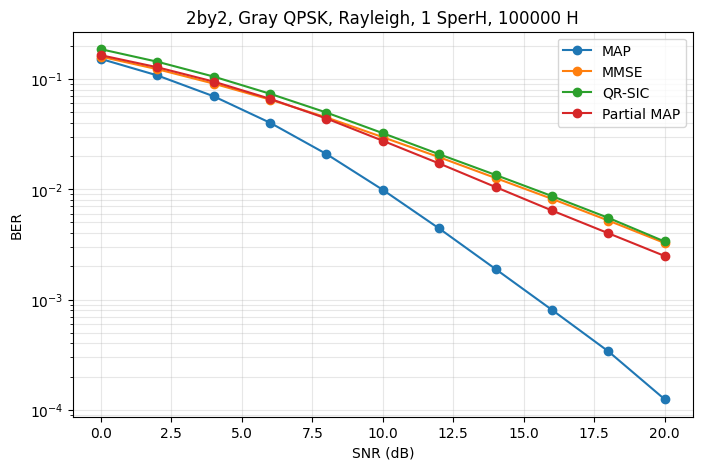

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

snr_db = np.asarray(SNR_DB)
fig, ax = plt.subplots(figsize=(8, 5))

for j, name in enumerate(models):
    points = ber[:, j]
    line, = ax.semilogy(
        snr_db, np.where(points > 0, points, np.nan), "o-", label=name
    )

    zero = points == 0
    if zero.any():
        ax.semilogy(
            snr_db[zero],
            np.full(zero.sum(), 1 / bits_per_snr),
            "v",
            color=line.get_color(),
        )

TITLE = f"{NT}by{NR}, Gray QPSK, Rayleigh, {SYMBOLS_PER_CHANNEL} SperH, {BLOCKS} H"
ax.set(xlabel="SNR (dB)", ylabel="BER",
       title=TITLE)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
print("Downward triangles: zero observed errors, shown at 1 / bits per SNR.")

plt.savefig(f'{TITLE}.png', dpi=300, bbox_inches='tight')
files.download(f'{TITLE}.png')

plt.show()